# Diabetes Prediction using Logistic Regression

**Goal:** Predict whether a patient has diabetes (1) or not (0) from medical measurements such as glucose, BMI, insulin and age.

**Model:** Logistic Regression  |  **Dataset:** Pima Indians Diabetes (768 patients)

In [1]:
# STEP 1 : Import Required Libraries
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
for folder in ["graphs", "confusion_matrix", "metrics", "predictions"]:
    os.makedirs(f"../outputs/{folder}", exist_ok=True)

print("All libraries imported successfully.")

All libraries imported successfully.


In [2]:
# STEP 2 : Load Dataset
df = pd.read_csv("../dataset/diabetes.csv")
print("Dataset loaded successfully.")

Dataset loaded successfully.


In [3]:
# STEP 3 : First Look at the Data
display(df.head())

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [4]:
# STEP 4 : Shape of the Dataset
print("Rows    :", df.shape[0])
print("Columns :", df.shape[1])

Rows    : 768
Columns : 9


In [5]:
# STEP 5 : Dataset Information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [6]:
# STEP 6 : Missing Values and Duplicates
print("Missing values (NaN):", df.isna().sum().sum())
print("Duplicate rows      :", df.duplicated().sum())

Missing values (NaN): 0
Duplicate rows      : 0


Outcome
0    500
1    268
Name: count, dtype: int64

Outcome
0    65.1
1    34.9
Name: proportion, dtype: float64


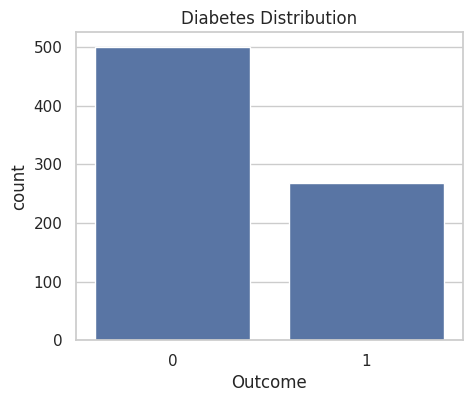

In [7]:
# STEP 7 : Target Variable Distribution
# Outcome = 1 -> diabetic, Outcome = 0 -> not diabetic
print(df["Outcome"].value_counts())
print()
print((df["Outcome"].value_counts(normalize=True) * 100).round(2))

plt.figure(figsize=(5,4))
sns.countplot(x="Outcome", data=df)
plt.title("Diabetes Distribution")
plt.show()

In [8]:
# STEP 8 : Hidden Missing Values (zeros that are impossible)
# A living person cannot have Glucose, BloodPressure, SkinThickness,
# Insulin or BMI equal to 0, so these zeros really mean "not recorded".
zero_cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
print("Number of zeros in each column:")
print((df[zero_cols] == 0).sum())

# Pregnancies = 0 is valid, so it is NOT changed.
df[zero_cols] = df[zero_cols].replace(0, np.nan)

print("\nMissing values after converting zeros to NaN:")
print(df.isna().sum()[df.isna().sum() > 0])

Number of zeros in each column:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

Missing values after converting zeros to NaN:


Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


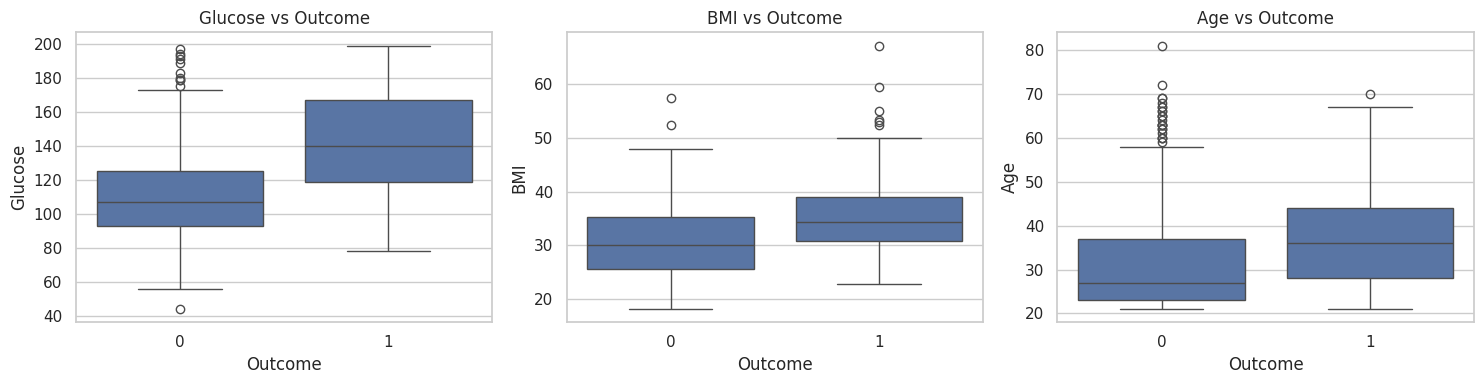

In [9]:
# STEP 9 : Exploratory Analysis
fig, ax = plt.subplots(1, 3, figsize=(15,4))
sns.boxplot(x="Outcome", y="Glucose", data=df, ax=ax[0])
ax[0].set_title("Glucose vs Outcome")
sns.boxplot(x="Outcome", y="BMI", data=df, ax=ax[1])
ax[1].set_title("BMI vs Outcome")
sns.boxplot(x="Outcome", y="Age", data=df, ax=ax[2])
ax[2].set_title("Age vs Outcome")
plt.tight_layout()
plt.show()

Glucose                     0.495
BMI                         0.314
Insulin                     0.303
SkinThickness               0.259
Age                         0.238
Pregnancies                 0.222
DiabetesPedigreeFunction    0.174
BloodPressure               0.171
Name: Outcome, dtype: float64


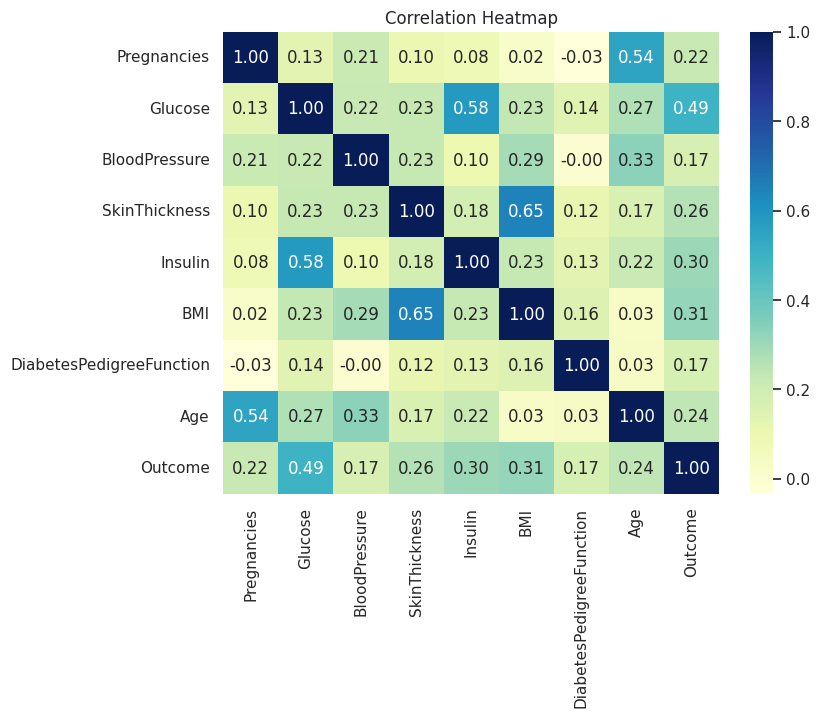

In [10]:
# STEP 10 : Correlation with the Target
corr = df.corr()["Outcome"].drop("Outcome").sort_values(ascending=False)
print(corr.round(3))

plt.figure(figsize=(8,6))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="YlGnBu")
plt.title("Correlation Heatmap")
plt.show()

In [11]:
# STEP 11 : Split Features and Target Variable
# All features are already numeric, so no encoding is needed.
from sklearn.model_selection import train_test_split

y = df["Outcome"]
X = df.drop(columns=["Outcome"])

print("Features Shape :", X.shape)
print("Target Shape   :", y.shape)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,     # 20% for testing
    random_state=42,    # same split every time
    stratify=y          # keep class ratio same in train and test
)

print("\nTraining Data :", X_train.shape)
print("Testing Data  :", X_test.shape)

Features Shape : (768, 8)
Target Shape   : (768,)

Training Data : (614, 8)
Testing Data  : (154, 8)


In [12]:
# STEP 12 : Handle Missing Values (AFTER the split, using training data only)
print("Missing values before filling:")
print(X_train.isna().sum()[X_train.isna().sum() > 0])

# Median of each column is learned from the TRAINING data only
medians = X_train.median()
X_train = X_train.fillna(medians)
X_test  = X_test.fillna(medians)

print("\nMissing values left in training data:", X_train.isna().sum().sum())
print("Missing values left in testing data :", X_test.isna().sum().sum())

Missing values before filling:
Glucose            4
BloodPressure     23
SkinThickness    175
Insulin          290
BMI                9
dtype: int64

Missing values left in training data: 0
Missing values left in testing data : 0


In [13]:
# STEP 13 : Feature Scaling
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # learn from training data only
X_test_scaled  = scaler.transform(X_test)        # apply the SAME scaler

print("Feature scaling completed successfully!")
print("Scaled Training Shape :", X_train_scaled.shape)
print("Scaled Testing Shape  :", X_test_scaled.shape)

Feature scaling completed successfully!
Scaled Training Shape : (614, 8)
Scaled Testing Shape  : (154, 8)


In [14]:
# STEP 14 : Train Logistic Regression Model
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(max_iter=1000, random_state=42)
logistic_model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully!")
print("Number of features used:", X_train_scaled.shape[1])

Logistic Regression model trained successfully!
Number of features used: 8


In [15]:
# STEP 15 : Make Predictions on Test Data
y_pred = logistic_model.predict(X_test_scaled)                 # labels (0 or 1)
y_prob = logistic_model.predict_proba(X_test_scaled)[:, 1]     # probability of diabetes

print("First 10 Predicted Values:", y_pred[:10])
print("First 10 Probabilities   :", y_prob[:10].round(3))

First 10 Predicted Values: [1 0 0 0 0 0 0 1 0 1]
First 10 Probabilities   : [0.61  0.118 0.293 0.251 0.034 0.168 0.488 0.924 0.081 0.839]


In [16]:
# STEP 16 : Evaluate the Model
from sklearn.metrics import accuracy_score, classification_report

accuracy = accuracy_score(y_test, y_pred)
print("=" * 50)
print("LOGISTIC REGRESSION MODEL PERFORMANCE")
print("=" * 50)
print(f"Model Accuracy : {accuracy:.4f}  ({accuracy*100:.2f}%)")
print()
print(classification_report(y_test, y_pred, target_names=["No Diabetes", "Diabetes"]))

LOGISTIC REGRESSION MODEL PERFORMANCE
Model Accuracy : 0.7078  (70.78%)

              precision    recall  f1-score   support

 No Diabetes       0.75      0.82      0.78       100
    Diabetes       0.60      0.50      0.55        54

    accuracy                           0.71       154
   macro avg       0.68      0.66      0.67       154
weighted avg       0.70      0.71      0.70       154



True Positive  (TP) : 27
False Negative (FN) : 27
False Positive (FP) : 18
True Negative  (TN) : 82


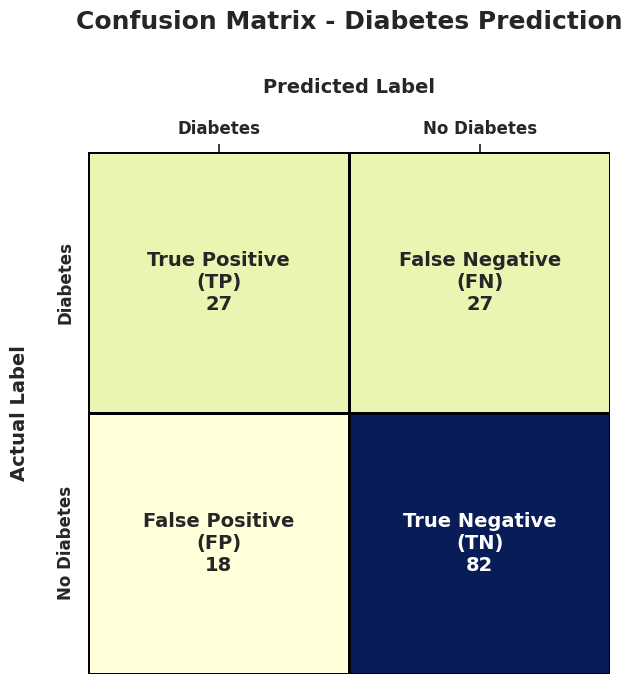

In [17]:
# STEP 17 : Confusion Matrix (positive class = Diabetes is shown first)
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred, labels=[1, 0])
TP, FN, FP, TN = cm.ravel()

print(f"True Positive  (TP) : {TP}")
print(f"False Negative (FN) : {FN}")
print(f"False Positive (FP) : {FP}")
print(f"True Negative  (TN) : {TN}")

box_labels = [[f"True Positive\n(TP)\n{TP}", f"False Negative\n(FN)\n{FN}"],
              [f"False Positive\n(FP)\n{FP}", f"True Negative\n(TN)\n{TN}"]]

plt.figure(figsize=(8,7))
ax = sns.heatmap(cm, annot=box_labels, fmt="", cmap="YlGnBu", linewidths=2,
                 linecolor="black", cbar=False, square=True,
                 annot_kws={"fontsize":14, "fontweight":"bold"})
ax.xaxis.tick_top()
ax.xaxis.set_label_position("top")
ax.set_xlabel("Predicted Label", fontsize=14, fontweight="bold", labelpad=20)
ax.set_ylabel("Actual Label", fontsize=14, fontweight="bold", labelpad=20)
ax.set_xticklabels(["Diabetes", "No Diabetes"], fontsize=12, fontweight="bold")
ax.set_yticklabels(["Diabetes", "No Diabetes"], fontsize=12, fontweight="bold", rotation=90)
plt.title("Confusion Matrix - Diabetes Prediction", fontsize=18, fontweight="bold", pad=35)
plt.tight_layout()
plt.savefig("../outputs/confusion_matrix/confusion_matrix_final.png", dpi=300, bbox_inches="tight")
plt.show()

AUC Score : 0.8130


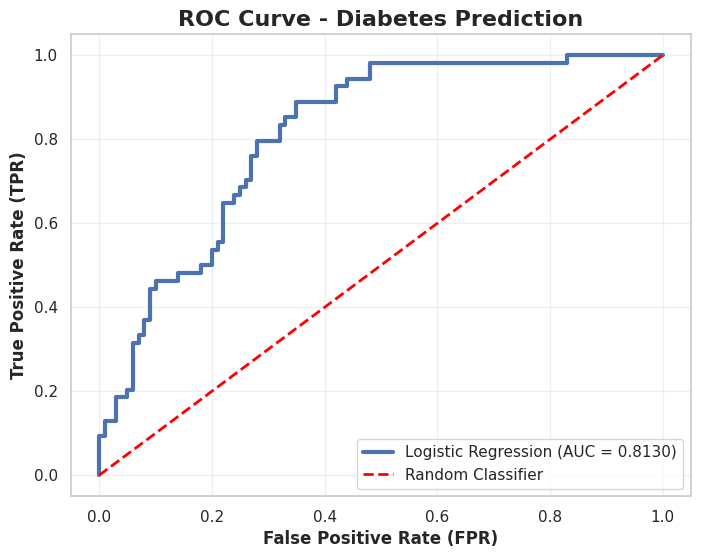

In [18]:
# STEP 18 : ROC Curve and AUC Score
from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc_score = roc_auc_score(y_test, y_prob)
print(f"AUC Score : {auc_score:.4f}")

plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, linewidth=3, label=f"Logistic Regression (AUC = {auc_score:.4f})")
plt.plot([0,1], [0,1], linestyle="--", linewidth=2, color="red", label="Random Classifier")
plt.title("ROC Curve - Diabetes Prediction", fontsize=16, fontweight="bold")
plt.xlabel("False Positive Rate (FPR)", fontsize=12, fontweight="bold")
plt.ylabel("True Positive Rate (TPR)", fontsize=12, fontweight="bold")
plt.grid(True, alpha=0.3)
plt.legend(loc="lower right")
plt.savefig("../outputs/graphs/roc_curve.png", dpi=300, bbox_inches="tight")
plt.show()

In [19]:
# STEP 19 : Precision, Recall, F1 and Specificity
from sklearn.metrics import precision_score, recall_score, f1_score

precision   = precision_score(y_test, y_pred)
recall      = recall_score(y_test, y_pred)
f1          = f1_score(y_test, y_pred)
specificity = TN / (TN + FP)

metrics_df = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "Specificity", "F1 Score", "ROC-AUC"],
    "Value": [round(accuracy,4), round(precision,4), round(recall,4),
              round(specificity,4), round(f1,4), round(auc_score,4)]
})
display(metrics_df)
metrics_df.to_csv("../outputs/metrics/model_metrics.csv", index=False)

,Metric,Value
0,Accuracy,0.7078
1,Precision,0.6000
2,Recall,0.5000
3,Specificity,0.8200
4,F1 Score,0.5455
5,ROC-AUC,0.8130


,Feature,Coefficient,Importance
1,Glucose,1.182567,1.182567
5,BMI,0.688652,0.688652
0,Pregnancies,0.377446,0.377446
6,DiabetesPedigreeFunction,0.233337,0.233337
7,Age,0.147794,0.147794
4,Insulin,-0.066119,0.066119
2,BloodPressure,-0.044111,0.044111
3,SkinThickness,0.028321,0.028321


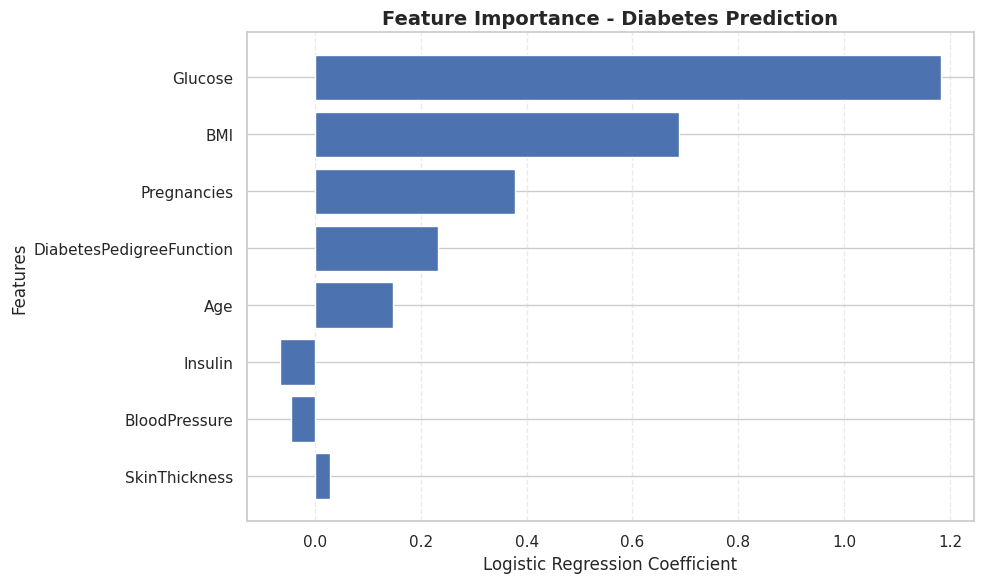

In [20]:
# STEP 20 : Feature Importance (Logistic Regression coefficients)
importance = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": logistic_model.coef_[0]
})
importance["Importance"] = importance["Coefficient"].abs()
importance = importance.sort_values(by="Importance", ascending=False)
display(importance)

plt.figure(figsize=(10,6))
plt.barh(importance["Feature"][::-1], importance["Coefficient"][::-1])
plt.title("Feature Importance - Diabetes Prediction", fontsize=14, fontweight="bold")
plt.xlabel("Logistic Regression Coefficient")
plt.ylabel("Features")
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig("../outputs/graphs/feature_importance.png", dpi=300)
plt.show()

In [21]:
# STEP 21 : Predict Diabetes for a New Patient
new_patient = pd.DataFrame([{
    "Pregnancies": 2, "Glucose": 150, "BloodPressure": 80, "SkinThickness": 30,
    "Insulin": 120, "BMI": 34.0, "DiabetesPedigreeFunction": 0.6, "Age": 45
}], columns=X.columns)

# Scale using the SAME scaler used during training
new_scaled  = scaler.transform(new_patient)
prediction  = logistic_model.predict(new_scaled)[0]
probability = logistic_model.predict_proba(new_scaled)[0][1]

display(new_patient)
print(f"Probability of Diabetes : {probability:.2%}")
print("Prediction :", "Patient is likely to have DIABETES." if prediction == 1
      else "Patient is likely NOT to have diabetes.")

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,2,150,80,30,120,34.0,0.6,45


Probability of Diabetes : 60.26%
Prediction : Patient is likely to have DIABETES.


In [22]:
# STEP 22 : Save Test Predictions
prediction_results = pd.DataFrame({
    "Actual_Diabetes": y_test.values,
    "Predicted_Diabetes": y_pred,
    "Probability_of_Diabetes": y_prob
})
display(prediction_results.head(10))
prediction_results.to_csv("../outputs/predictions/diabetes_predictions.csv", index=False)

,Actual_Diabetes,Predicted_Diabetes,Probability_of_Diabetes
0,0,1,0.609700
1,0,0,0.118291
2,0,0,0.293426
3,1,0,0.250801
4,0,0,0.033527
5,0,0,0.168478
6,1,0,0.488064
7,1,1,0.923665
8,0,0,0.081422
9,0,1,0.838593


## Investigation: Does the choice of metric change the conclusion?

We keep the **same model and same test set** and only change the decision threshold (0.3, 0.5, 0.7).

For a diabetes screening test, missing a diabetic patient (false negative) is usually worse than a false alarm, so **recall** matters.

In [23]:
# STEP 23 : Threshold Comparison
thresholds_list = [0.3, 0.5, 0.7]
results = []

for t in thresholds_list:
    y_pred_t = (y_prob >= t).astype(int)
    results.append({
        "Threshold": t,
        "Accuracy":  round(accuracy_score(y_test, y_pred_t), 4),
        "Precision": round(precision_score(y_test, y_pred_t, zero_division=0), 4),
        "Recall":    round(recall_score(y_test, y_pred_t), 4),
        "F1-Score":  round(f1_score(y_test, y_pred_t), 4)
    })

threshold_df = pd.DataFrame(results)
display(threshold_df)
threshold_df.to_csv("../outputs/metrics/threshold_comparison.csv", index=False)

,Threshold,Accuracy,Precision,Recall,F1-Score
0,0.3,0.7403,0.5972,0.7963,0.6825
1,0.5,0.7078,0.6000,0.5000,0.5455
2,0.7,0.7273,0.7143,0.3704,0.4878


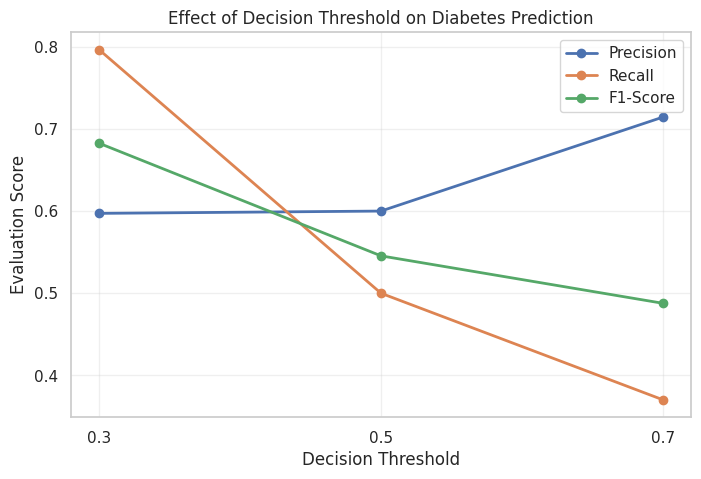

In [24]:
# STEP 24 : Threshold vs Evaluation Metrics Graph
plt.figure(figsize=(8,5))
for col in ["Precision", "Recall", "F1-Score"]:
    plt.plot(threshold_df["Threshold"], threshold_df[col], marker="o", linewidth=2, label=col)
plt.title("Effect of Decision Threshold on Diabetes Prediction")
plt.xlabel("Decision Threshold")
plt.ylabel("Evaluation Score")
plt.xticks([0.3, 0.5, 0.7])
plt.grid(True, alpha=0.3)
plt.legend()
plt.savefig("../outputs/graphs/threshold_comparison.png", dpi=300, bbox_inches="tight")
plt.show()